In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import new_data_loader
import pandas as pd
import numpy as np

importlib.reload(new_data_loader)

begin_inventory, end_inventory, purchase_prices, purchases, vendor_invoice = new_data_loader.load_data()

- Top 10 vendors by total purchase spending.
- Top 10 products by purchase expenditure.
- Monthly purchasing trends.
- Vendors with the highest freight percentage.
- Vendor price comparison.
- Top 10 stores by closing inventory.
- Products with unusually high closing inventory.
- Average delivery duration by vendor.
- Supplier spending concentration.

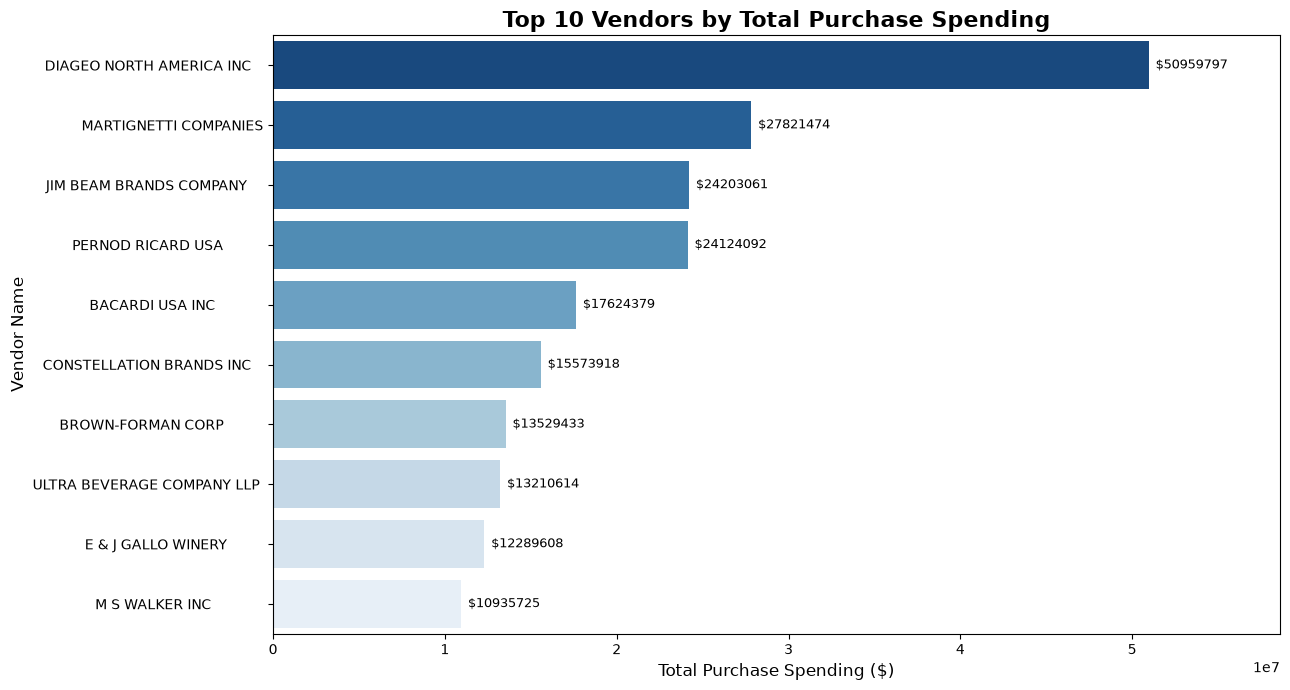

In [13]:
# Top 10 vendors by total purchase spending.

# Calculate top 10 vendors by purchase spending
top_vendors = (
    purchases.groupby('VendorName')['Dollars']
    .sum()
    .reset_index()
    .sort_values('Dollars', ascending=False)
    .head(10)
)

plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_vendors,
    x='Dollars',
    y='VendorName',
    hue='VendorName',
    palette='Blues_r',
    legend=False
)

# Add value labels to every bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='$%.0f',
        padding=5,
        fontsize=9
    )

plt.title('Top 10 Vendors by Total Purchase Spending',
          fontsize=16, fontweight='bold')

plt.xlabel('Total Purchase Spending ($)', fontsize=12)
plt.ylabel('Vendor Name', fontsize=12)

# Add extra space on the right for labels
plt.xlim(0, top_vendors['Dollars'].max() * 1.15)

plt.tight_layout()
plt.show()

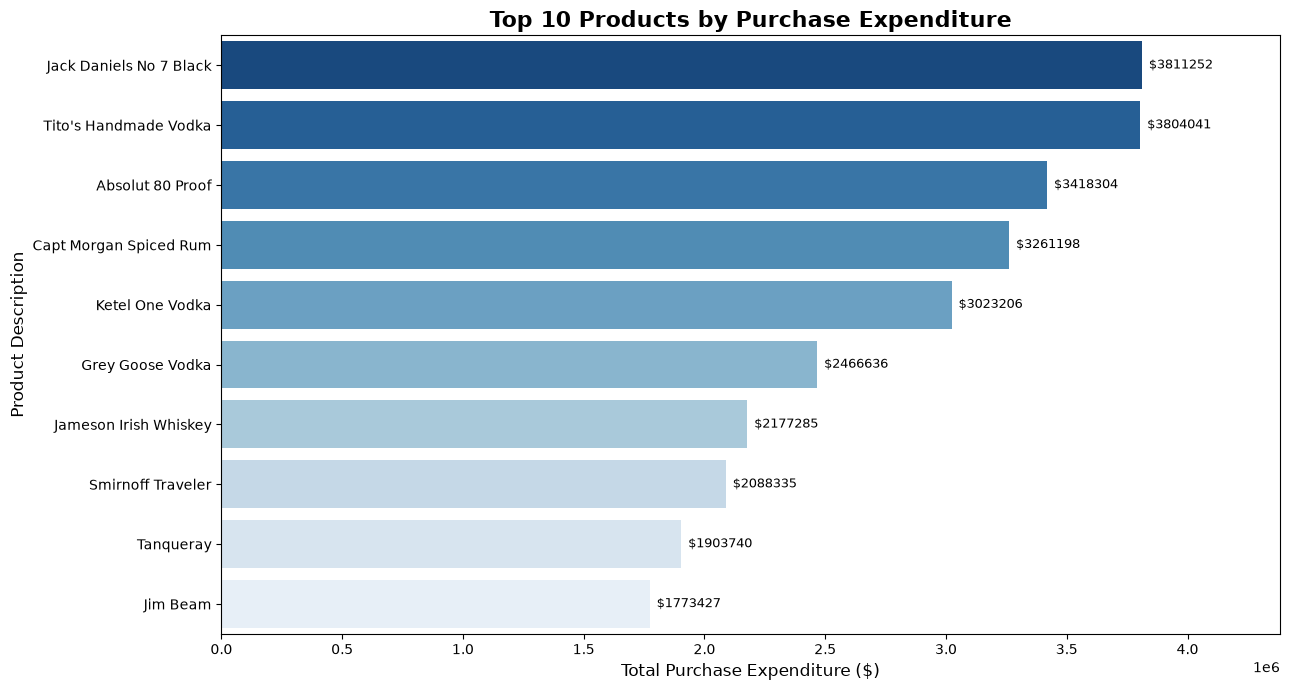

In [14]:
# Top 10 products by purchase expenditure.

# Calculate top 10 products by purchase expenditure
top_products = (
    purchases.groupby(['Brand', 'Description', 'Size'])['Dollars']
    .sum()
    .reset_index()
    .sort_values('Dollars', ascending=False)
    .head(10)
)

# Create visualization
plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=top_products,
    x='Dollars',
    y='Description',
    hue='Description',
    palette='Blues_r',
    legend=False
)

# Add value labels to every bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='$%.0f',
        padding=5,
        fontsize=9
    )

plt.title(
    'Top 10 Products by Purchase Expenditure',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Total Purchase Expenditure ($)', fontsize=12)
plt.ylabel('Product Description', fontsize=12)

# Space for value labels
plt.xlim(0, top_products['Dollars'].max() * 1.15)

plt.tight_layout()
plt.show()

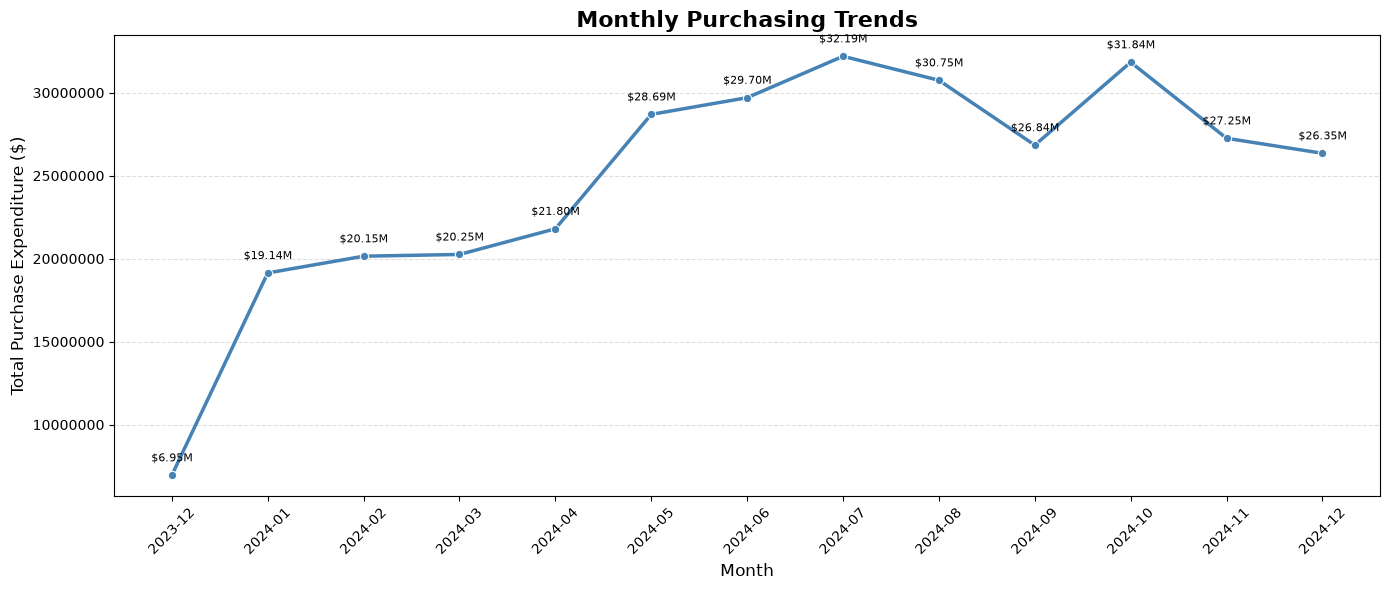

In [18]:
# Monthly purchasing trends.

# Extract month from PODate
purchases['Month'] = purchases['PODate'].dt.to_period('M')

# Calculate monthly purchase expenditure
monthly_purchases = (
    purchases.groupby('Month')['Dollars']
    .sum()
    .reset_index()
)

# Convert Period to string for plotting
monthly_purchases['Month'] = monthly_purchases['Month'].astype(str)

# Create line chart
plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=monthly_purchases,
    x='Month',
    y='Dollars',
    marker='o',
    linewidth=2.5,
    color='steelblue'
)

# Add value labels
for x, y in zip(monthly_purchases['Month'],
                monthly_purchases['Dollars']):
    ax.annotate(
        f'${y/1_000_000:.2f}M',
        (x, y),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8
    )

plt.title(
    'Monthly Purchasing Trends',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Purchase Expenditure ($)', fontsize=12)

plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

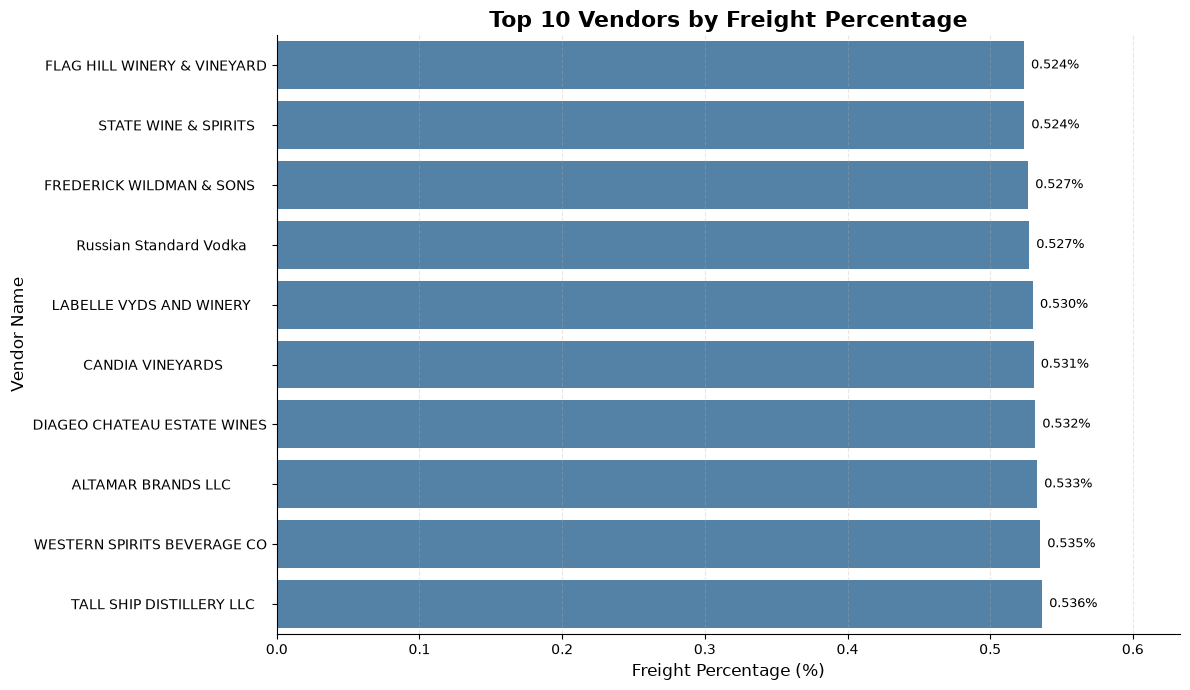

In [22]:
# Vendors with the highest freight percentage.

vendor_freight = (
    vendor_invoice.groupby(['VendorNumber', 'VendorName'])
    .agg(
        Total_Invoice_Value=('Dollars', 'sum'),
        Total_Freight=('Freight', 'sum')
    )
    .reset_index()
)

vendor_freight['Freight_Percentage'] = (
    vendor_freight['Total_Freight'] /
    vendor_freight['Total_Invoice_Value']
) * 100

top_freight_vendors = (
    vendor_freight[
        vendor_freight['Total_Invoice_Value'] >= 10000
    ]
    .nlargest(10, 'Freight_Percentage')
    .sort_values('Freight_Percentage', ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_freight_vendors,
    x='Freight_Percentage',
    y='VendorName',
    color='steelblue'
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f%%',
        padding=5,
        fontsize=9
    )

plt.title(
    'Top 10 Vendors by Freight Percentage',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Freight Percentage (%)', fontsize=12)
plt.ylabel('Vendor Name', fontsize=12)

plt.xlim(0, top_freight_vendors['Freight_Percentage'].max() * 1.18)

plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval,Freight_percentage
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,NaN,1.619528
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,NaN,6.097474
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,NaN,4.324578
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,NaN,2.134943
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,NaN,2.764173


In [48]:
# Vendor price comparison.

vendor_price_comparison = (
    purchases.groupby(['VendorNumber', 'VendorName'])
    .agg(
        Total_Quantity=('Quantity', 'sum'),
        Total_Purchase_Value=('Dollars', 'sum')
    )
    .reset_index()
)

vendor_price_comparison['Avg_Purchase_Cost'] = (
    vendor_price_comparison['Total_Purchase_Value'] /
    vendor_price_comparison['Total_Quantity']
)

vendor_price_comparison = vendor_price_comparison.sort_values(
    'Avg_Purchase_Cost', ascending=False
)

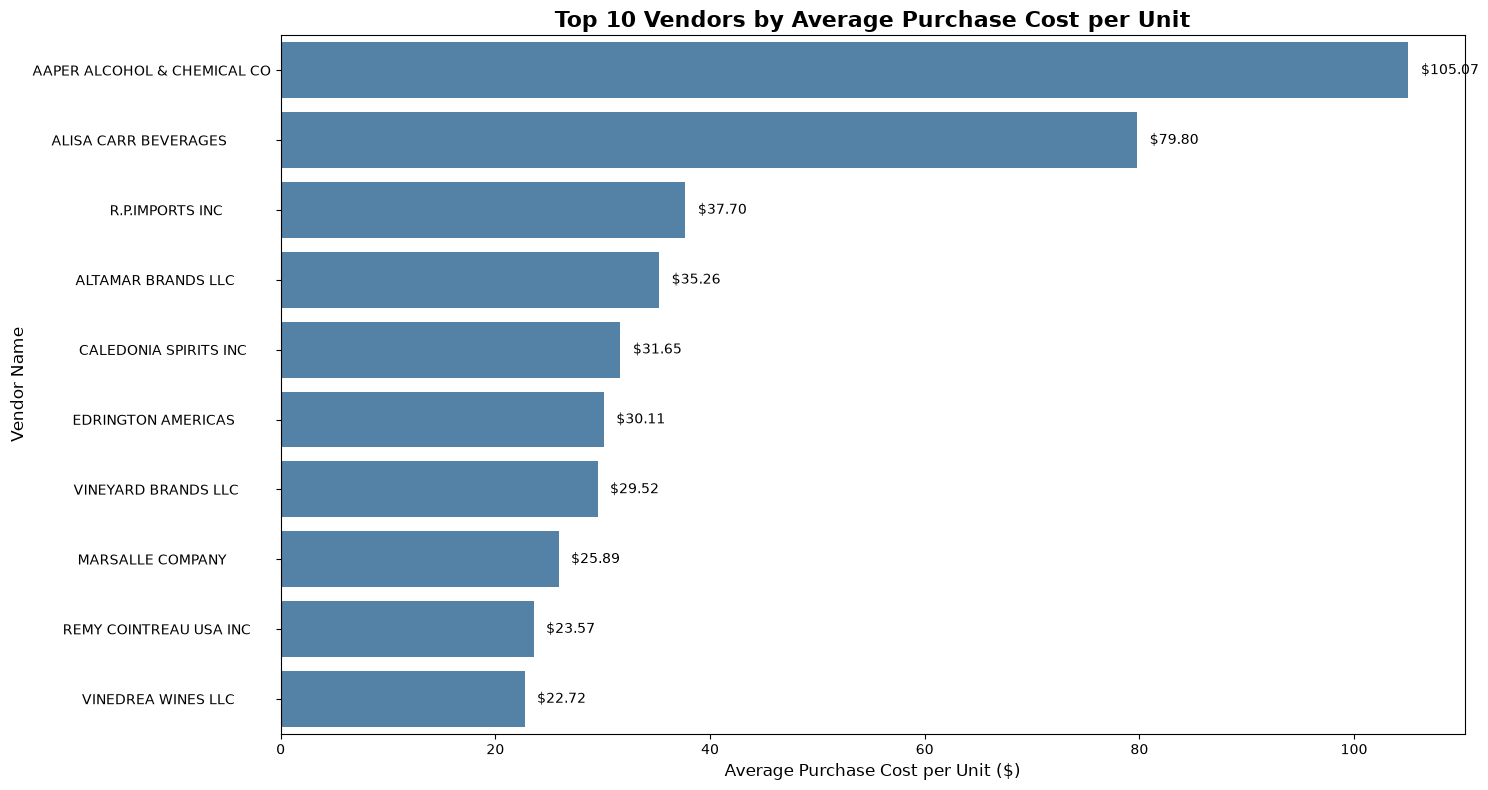

In [40]:
plt.figure(figsize=(15, 8))

ax = sns.barplot(
    data=vendor_price_comparison.head(10),
    x='Avg_Purchase_Cost',
    y='VendorName',
    color='steelblue'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.2f",
        padding=9
    )
    
plt.title(
    'Top 10 Vendors by Average Purchase Cost per Unit',
    fontsize=16,
    fontweight='bold'
)    

plt.xlabel('Average Purchase Cost per Unit ($)', fontsize=12)
plt.ylabel('Vendor Name', fontsize = 12)

plt.tight_layout()
plt.show()

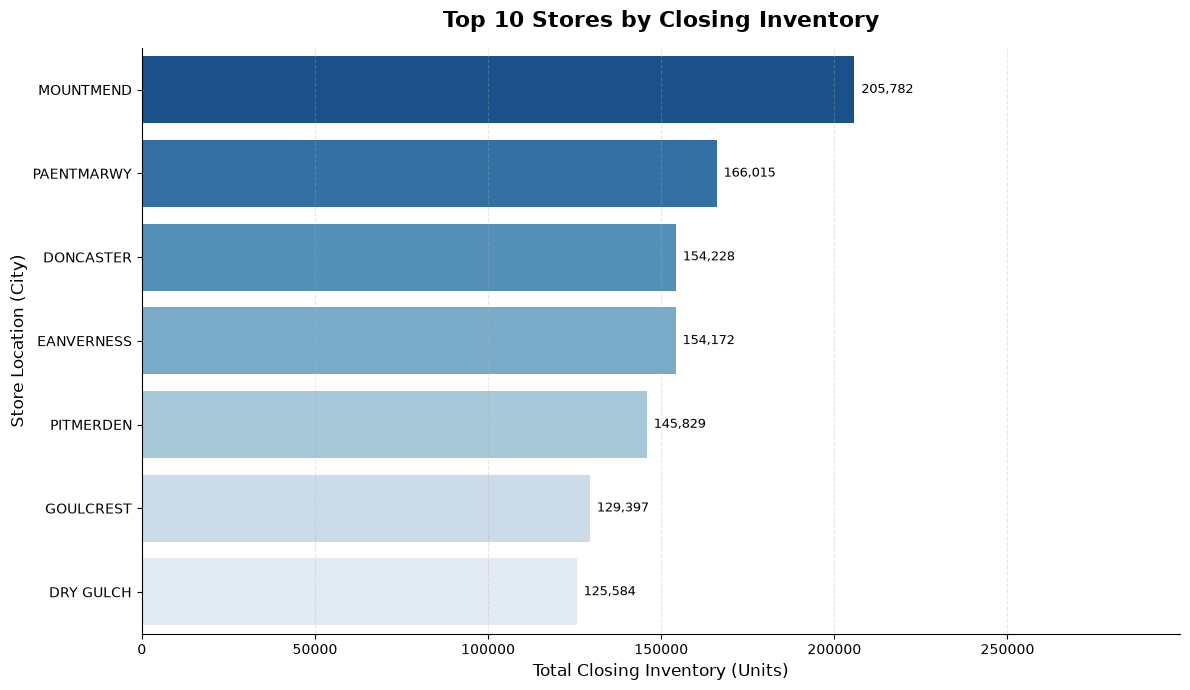

In [47]:
# Top 10 stores by closing inventory.
top_closing_stores=(
    end_inventory.groupby(['Store', 'City'])['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

ax=sns.barplot(
    data=top_closing_stores,
    x='onHand',
    y='City',
    hue='City',
    palette='Blues_r',
    errorbar=None,
    legend=False
)

# Add stock quantity labels
for containers in ax.containers:
    ax.bar_label(
        containers,
        fmt='{:,.0f}',
        padding=5,
        fontsize=9
    )
    
plt.title(
    'Top 10 Stores by Closing Inventory',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Total Closing Inventory (Units)', fontsize=12)
plt.ylabel('Store Location (City)', fontsize=12)

plt.xlim(0, top_closing_stores['onHand'].max()*1.15)

plt.grid(axis='x',linestyle='--',alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

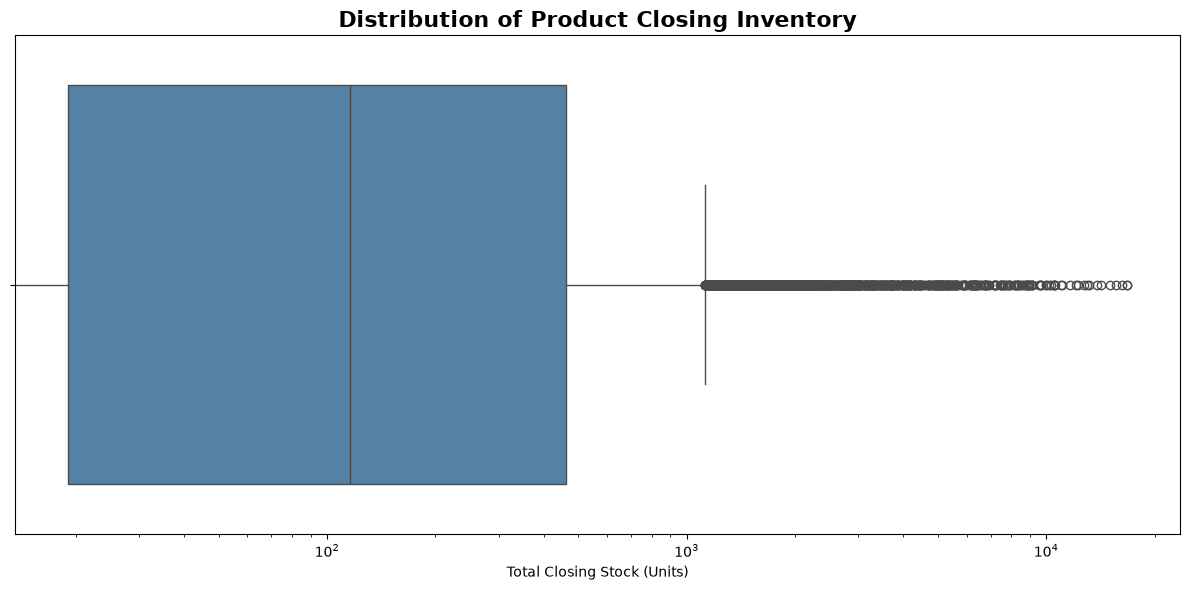

In [51]:
# Products with unusually high closing inventory.

product_closing_stock = (
    end_inventory.groupby(
        ['Brand', 'Description', 'Size']
    )['onHand']
    .sum()
    .reset_index(name="Total_Closing_Stock")
)

plt.figure(figsize=(12, 6))

ax=sns.boxplot(
    x=product_closing_stock['Total_Closing_Stock'],
    color='steelblue',
    showfliers=True
)

ax.set_xscale('log')

plt.title(
    'Distribution of Product Closing Inventory',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Total Closing Stock (Units)')
plt.tight_layout()
plt.show()

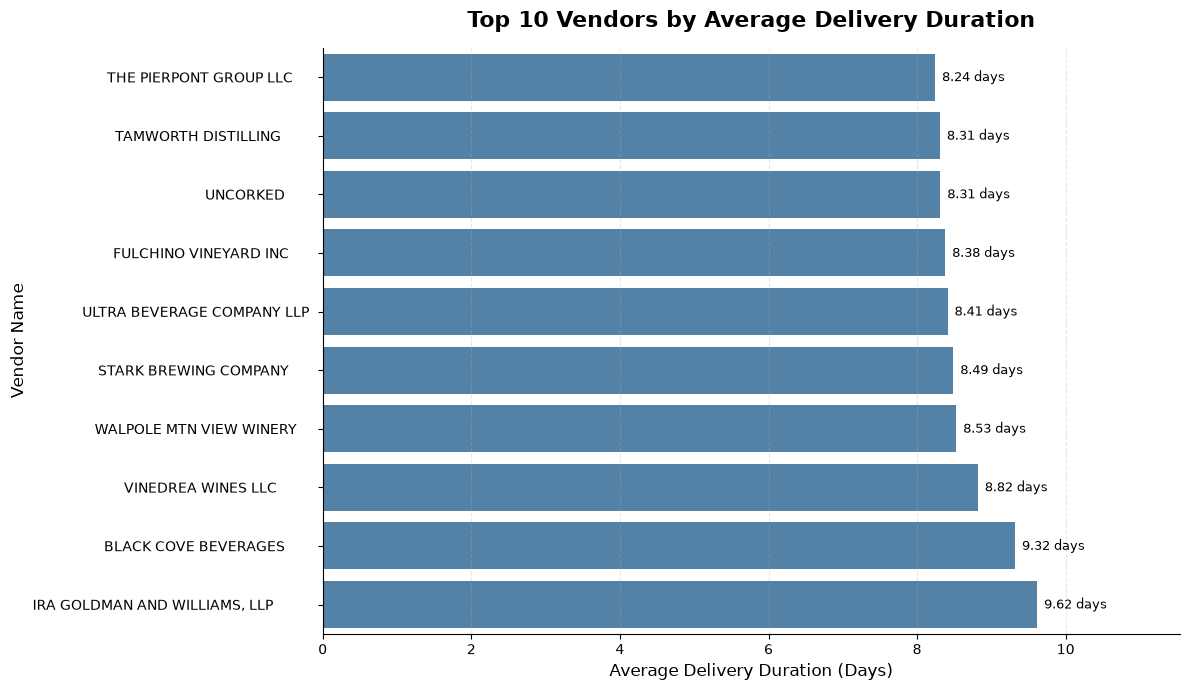

In [54]:
# Average delivery duration by vendor.
vendor_delivery = (
    purchases.dropna(subset=['DeliveryDay'])
    .groupby(['VendorNumber', 'VendorName'])
    .agg(
        Average_Delivery_Days=('DeliveryDay', 'mean'),
        Purchase_Count=('DeliveryDay', 'count')
    )
    .reset_index()
)

# Consider vendors with at least 10 purchase records
vendor_delivery = vendor_delivery[
    vendor_delivery['Purchase_Count'] >= 10
]

# Select top 10 vendors with longest delivery duration
top_delivery_vendors = (
    vendor_delivery
    .nlargest(10, 'Average_Delivery_Days')
    .sort_values('Average_Delivery_Days', ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_delivery_vendors,
    x='Average_Delivery_Days',
    y='VendorName',
    color='steelblue',
    errorbar=None
)

# Add value labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f days',
        padding=5,
        fontsize=9
    )

plt.title(
    'Top 10 Vendors by Average Delivery Duration',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Average Delivery Duration (Days)', fontsize=12)
plt.ylabel('Vendor Name', fontsize=12)

plt.xlim(0, top_delivery_vendors['Average_Delivery_Days'].max() * 1.2)

plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()
plt.show()

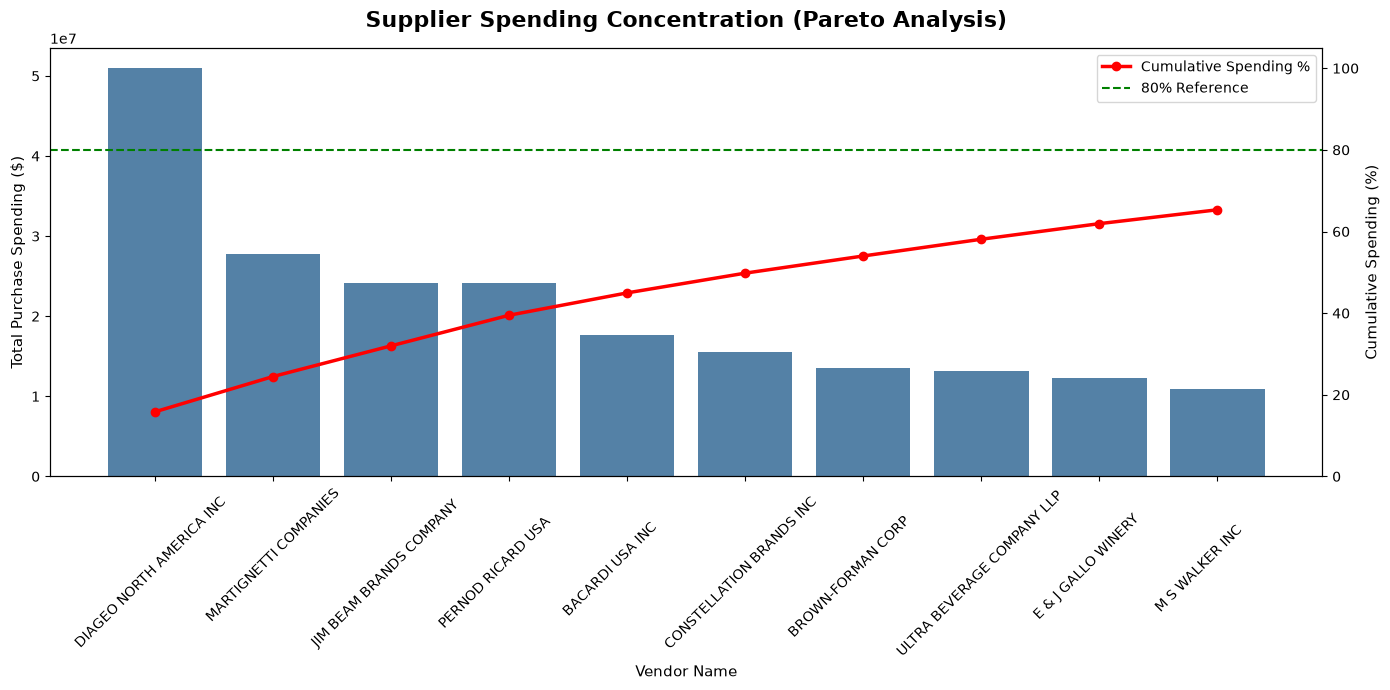

In [56]:
# Supplier spending concentration.
# Calculate total purchase spending by vendor
supplier_spending = (
    purchases.groupby('VendorName')['Dollars']
    .sum()
    .reset_index()
    .sort_values('Dollars', ascending=False)
)

# Calculate percentage contribution
supplier_spending['Spending_Percentage'] = (
    supplier_spending['Dollars'] /
    supplier_spending['Dollars'].sum()
) * 100

# Calculate cumulative percentage
supplier_spending['Cumulative_Percentage'] = (
    supplier_spending['Spending_Percentage'].cumsum()
)

# Take top 10 vendors
top_suppliers = supplier_spending.head(10).copy()

fig, ax1 = plt.subplots(figsize=(14, 7))

# Bar chart: purchase spending
sns.barplot(
    data=top_suppliers,
    x='VendorName',
    y='Dollars',
    color='steelblue',
    ax=ax1,
    errorbar=None
)

ax1.set_xlabel('Vendor Name', fontsize=11)
ax1.set_ylabel('Total Purchase Spending ($)', fontsize=11)

ax1.set_title(
    'Supplier Spending Concentration (Pareto Analysis)',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax1.tick_params(axis='x', rotation=45)

# Line chart: cumulative percentage
ax2 = ax1.twinx()

ax2.plot(
    range(len(top_suppliers)),
    top_suppliers['Cumulative_Percentage'],
    color='red',
    marker='o',
    linewidth=2.5,
    label='Cumulative Spending %'
)

ax2.set_ylabel('Cumulative Spending (%)', fontsize=11)
ax2.set_ylim(0, 105)

# Add 80% reference line
ax2.axhline(
    80,
    color='green',
    linestyle='--',
    linewidth=1.5,
    label='80% Reference'
)

ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [52]:
purchases.head()

,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification,DeliveryDay,Month
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1,12,2023-12
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1,10,2023-12
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1,11,2023-12
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1,10,2023-12
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1,9,2023-12
